<a href="https://colab.research.google.com/github/nishtha318/Financial-Distress-Prediction/blob/main/Financial_distress_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Financial Distress Prediction Using Machine Learning**

## Project Objective

The objective of this project is to develop a machine learning-based
system that analyzes financial indicators of companies and predicts
whether a company is at risk of bankruptcy.

The project aims to explore financial patterns associated with corporate
distress and evaluate different machine learning models for reliable
classification of companies into bankrupt and non-bankrupt categories.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith(('.csv', '.xlsx', '.xls')):
            print(os.path.join(root, file))

/content/drive/MyDrive/data.csv


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/data.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 6819
Columns: 96


## 1. Dataset Overview

The dataset is inspected to understand its structure, including the
available features, target variable, data types, and number of observations.
This initial inspection helps identify the nature of the data before
performing preprocessing and exploratory analysis.

In [ ]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (6819, 96)

First 5 Rows:


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [ ]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Column Names:
['Bankrupt?', ' ROA(C) before interest and depreciation before interest', ' ROA(A) before interest and % after tax', ' ROA(B) before interest and depreciation after tax', ' Operating Gross Margin', ' Realized Sales Gross Margin', ' Operating Profit Rate', ' Pre-tax net Interest Rate', ' After-tax net Interest Rate', ' Non-industry income and expenditure/revenue', ' Continuous interest rate (after tax)', ' Operating Expense Rate', ' Research and development expense rate', ' Cash flow rate', ' Interest-bearing debt interest rate', ' Tax rate (A)', ' Net Value Per Share (B)', ' Net Value Per Share (A)', ' Net Value Per Share (C)', ' Persistent EPS in the Last Four Seasons', ' Cash Flow Per Share', ' Revenue Per Share (Yuan ¥)', ' Operating Profit Per Share (Yuan ¥)', ' Per Share Net profit before tax (Yuan ¥)', ' Realized Sales Gross Profit Growth Rate', ' Operating Profit Growth Rate', ' After-tax Net Profit Growth Rate', ' Regular Net Profit Growth Rate', ' Continuous Net 

## 2. Cleaning Column Names

The dataset contains leading spaces in several column names. These spaces
are removed to make the column names cleaner and easier to use during
data analysis and model development.

In [ ]:
# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

print("Column names cleaned successfully.")
print(df.columns.tolist()[:10])

Column names cleaned successfully.
['Bankrupt?', 'ROA(C) before interest and depreciation before interest', 'ROA(A) before interest and % after tax', 'ROA(B) before interest and depreciation after tax', 'Operating Gross Margin', 'Realized Sales Gross Margin', 'Operating Profit Rate', 'Pre-tax net Interest Rate', 'After-tax net Interest Rate', 'Non-industry income and expenditure/revenue']


In [ ]:
missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

print("\nColumns with missing values:")
display(missing_values[missing_values > 0])

Total missing values: 0

Columns with missing values:


,0


## 3. Target Variable Distribution

The target variable `Bankrupt?` is analyzed to determine the number and
proportion of bankrupt and non-bankrupt companies. This helps identify
whether the dataset is balanced or imbalanced.

In [ ]:
target_counts = df['Bankrupt?'].value_counts()

print("Number of companies in each class:")
print(target_counts)

print("\nPercentage distribution:")
print((target_counts / len(df) * 100).round(2))

Number of companies in each class:
Bankrupt?
0    6599
1     220
Name: count, dtype: int64

Percentage distribution:
Bankrupt?
0    96.77
1     3.23
Name: count, dtype: float64


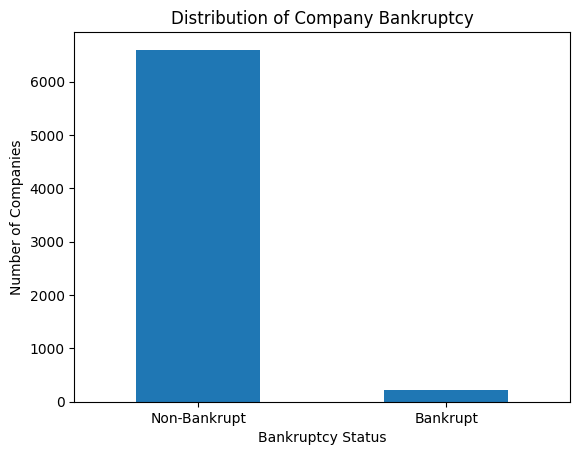

In [ ]:
import matplotlib.pyplot as plt

target_counts.plot(kind='bar')

plt.title("Distribution of Company Bankruptcy")
plt.xlabel("Bankruptcy Status")
plt.ylabel("Number of Companies")
plt.xticks([0, 1], ["Non-Bankrupt", "Bankrupt"], rotation=0)
plt.show()

## 4. Descriptive Statistics

Descriptive statistics are used to understand the central tendency,
spread, and range of the financial features before further analysis.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Bankrupt?,6819.0,0.032263,0.176710,0.0,0.000000,0.000000,0.000000,1.0
ROA(C) before interest and depreciation before interest,6819.0,0.505180,0.060686,0.0,0.476527,0.502706,0.535563,1.0
ROA(A) before interest and % after tax,6819.0,0.558625,0.065620,0.0,0.535543,0.559802,0.589157,1.0
ROA(B) before interest and depreciation after tax,6819.0,0.553589,0.061595,0.0,0.527277,0.552278,0.584105,1.0
Operating Gross Margin,6819.0,0.607948,0.016934,0.0,0.600445,0.605997,0.613914,1.0
...,...,...,...,...,...,...,...,...
Liability to Equity,6819.0,0.280365,0.014463,0.0,0.276944,0.278778,0.281449,1.0
Degree of Financial Leverage (DFL),6819.0,0.027541,0.015668,0.0,0.026791,0.026808,0.026913,1.0
Interest Coverage Ratio (Interest expense to EBIT),6819.0,0.565358,0.013214,0.0,0.565158,0.565252,0.565725,1.0
Net Income Flag,6819.0,1.000000,0.000000,1.0,1.000000,1.000000,1.000000,1.0


## 5. Feature Variability Check

Features with no variation have the same value for every observation and
therefore cannot help a machine learning model distinguish between
different companies. These features are identified before model training.

In [ ]:
# Find features with only one unique value
unique_counts = df.nunique()

constant_features = unique_counts[unique_counts == 1]

print("Constant features:")
print(constant_features)

print("\nNumber of constant features:", len(constant_features))

Constant features:
Net Income Flag    1
dtype: int64

Number of constant features: 1


In [ ]:
df = df.drop(columns=constant_features.index)

print("Dataset shape after removing constant features:", df.shape)

Dataset shape after removing constant features: (6819, 95)


In [ ]:
# Calculate standard deviation of each feature
feature_std = df.drop(columns='Bankrupt?').std().sort_values(ascending=False)

print("Top 10 features by standard deviation:")
display(feature_std.head(10))

Top 10 features by standard deviation:


,0
Quick Asset Turnover Rate,3.374944e+09
Inventory Turnover Rate (times),3.247967e+09
Operating Expense Rate,3.237684e+09
Cash Turnover Rate,2.938623e+09
Total Asset Growth Rate,2.897718e+09
Current Asset Turnover Rate,2.821161e+09
Research and development expense rate,2.598292e+09
Fixed Assets Turnover Frequency,2.477557e+09
Inventory/Current Liability,5.820516e+08
Long-term Liability to Current Assets,5.702706e+08


In [ ]:
# Check the minimum and maximum of the features with very large spread

top_features = feature_std.head(10).index

display(df[top_features].describe().T[['min', '50%', 'max', 'std']])

,min,50%,max,std
Quick Asset Turnover Rate,0.0,2.247728e-04,1.000000e+10,3.374944e+09
Inventory Turnover Rate (times),0.0,7.646743e-04,9.990000e+09,3.247967e+09
Operating Expense Rate,0.0,2.777589e-04,9.990000e+09,3.237684e+09
Cash Turnover Rate,0.0,1.080000e+09,1.000000e+10,2.938623e+09
Total Asset Growth Rate,0.0,6.400000e+09,9.990000e+09,2.897718e+09
Current Asset Turnover Rate,0.0,1.987816e-04,1.000000e+10,2.821161e+09
Research and development expense rate,0.0,5.090000e+08,9.980000e+09,2.598292e+09
Fixed Assets Turnover Frequency,0.0,5.930942e-04,9.990000e+09,2.477557e+09
Inventory/Current Liability,0.0,6.497335e-03,9.910000e+09,5.820516e+08
Long-term Liability to Current Assets,0.0,1.974619e-03,9.540000e+09,5.702706e+08


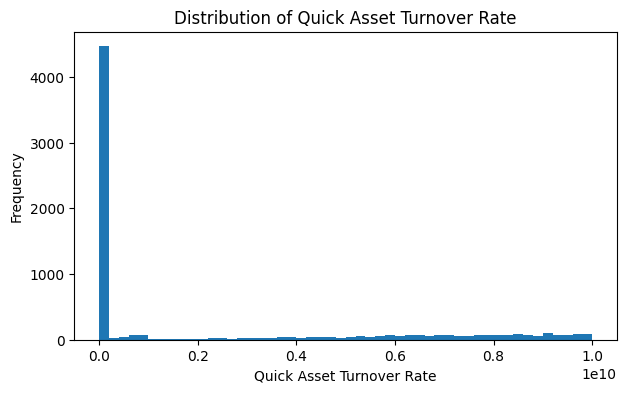

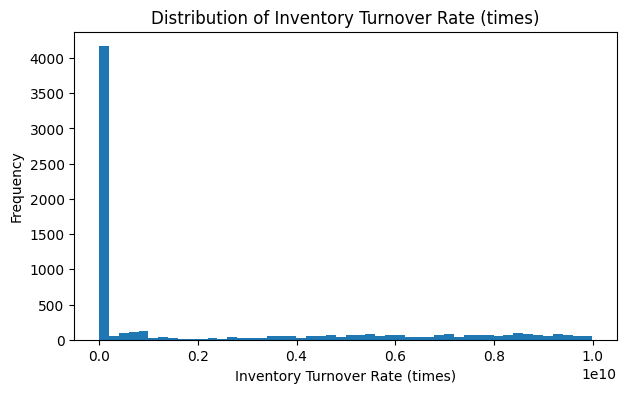

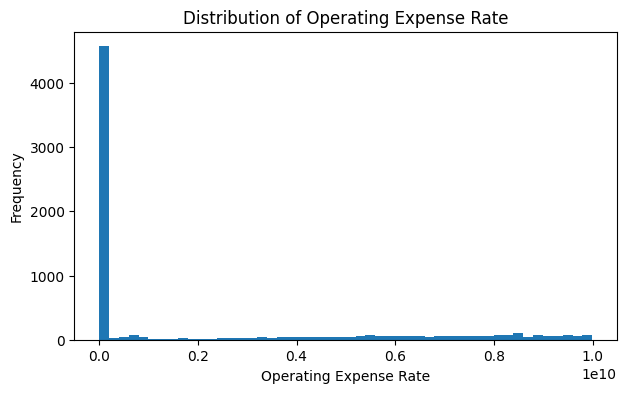

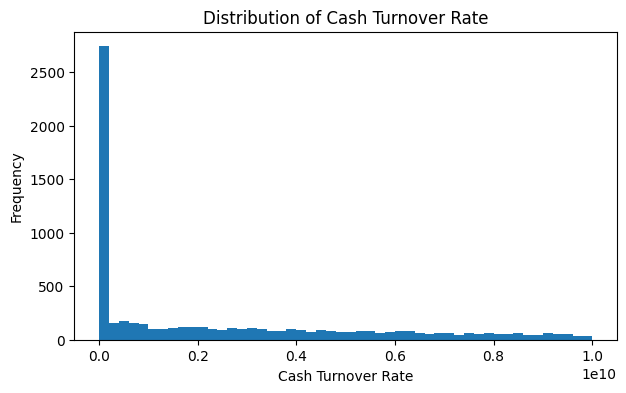

In [ ]:
selected_features = [
    'Quick Asset Turnover Rate',
    'Inventory Turnover Rate (times)',
    'Operating Expense Rate',
    'Cash Turnover Rate'
]

for feature in selected_features:
    plt.figure(figsize=(7, 4))
    plt.hist(df[feature], bins=50)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.show()

##  Outlier Handling

The dataset contains a considerable number of potential outliers in several
financial indicators, as identified using the IQR method.

However, these observations are not automatically treated as erroneous
because extreme financial ratios may represent genuine differences in a
company's financial condition.

Therefore, observations are retained at this stage rather than being
removed solely on the basis of the IQR rule. The effect of extreme values
will be considered when selecting and evaluating the machine-learning
models.

In [ ]:
# Calculate IQR-based outliers

features = df.drop(columns='Bankrupt?')

Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)
IQR = Q3 - Q1

outlier_counts = (
    ((features < (Q1 - 1.5 * IQR)) |
     (features > (Q3 + 1.5 * IQR)))
    .sum()
    .sort_values(ascending=False)
)

display(outlier_counts.head(15).to_frame("Outlier Count"))

,Outlier Count
Degree of Financial Leverage (DFL),1503
Interest Coverage Ratio (Interest expense to EBIT),1421
Fixed Assets Turnover Frequency,1418
Current Asset Turnover Rate,1399
Total Asset Growth Rate,1381
Interest Expense Ratio,1362
Cash Flow to Liability,1212
No-credit Interval,1139
Non-industry income and expenditure/revenue,1094
Cash Flow to Sales,1052


## 7. Feature Correlation with Bankruptcy

Correlation analysis is used to examine the linear relationship between
the financial indicators and the bankruptcy target. This provides an
initial understanding of which variables may be associated with financial
distress.

In [ ]:
correlations = df.corr(numeric_only=True)['Bankrupt?'].sort_values()

print("Features most negatively correlated with bankruptcy:")
display(correlations.head(10))

print("\nFeatures most positively correlated with bankruptcy:")
display(correlations.tail(10))

Features most negatively correlated with bankruptcy:


,Bankrupt?
Net Income to Total Assets,-0.315457
ROA(A) before interest and % after tax,-0.282941
ROA(B) before interest and depreciation after tax,-0.273051
ROA(C) before interest and depreciation before interest,-0.260807
Net worth/Assets,-0.250161
Persistent EPS in the Last Four Seasons,-0.219560
Retained Earnings to Total Assets,-0.217779
Net profit before tax/Paid-in capital,-0.207857
Per Share Net profit before tax (Yuan ¥),-0.201395
Working Capital to Total Assets,-0.193083



Features most positively correlated with bankruptcy:


,Bankrupt?
Total expense/Assets,0.139049
Liability-Assets Flag,0.139212
Current Liabilities/Equity,0.153828
Current Liability to Equity,0.153828
Liability to Equity,0.166812
Current Liability to Current Assets,0.171306
Borrowing dependency,0.176543
Current Liability to Assets,0.194494
Debt ratio %,0.250161
Bankrupt?,1.000000


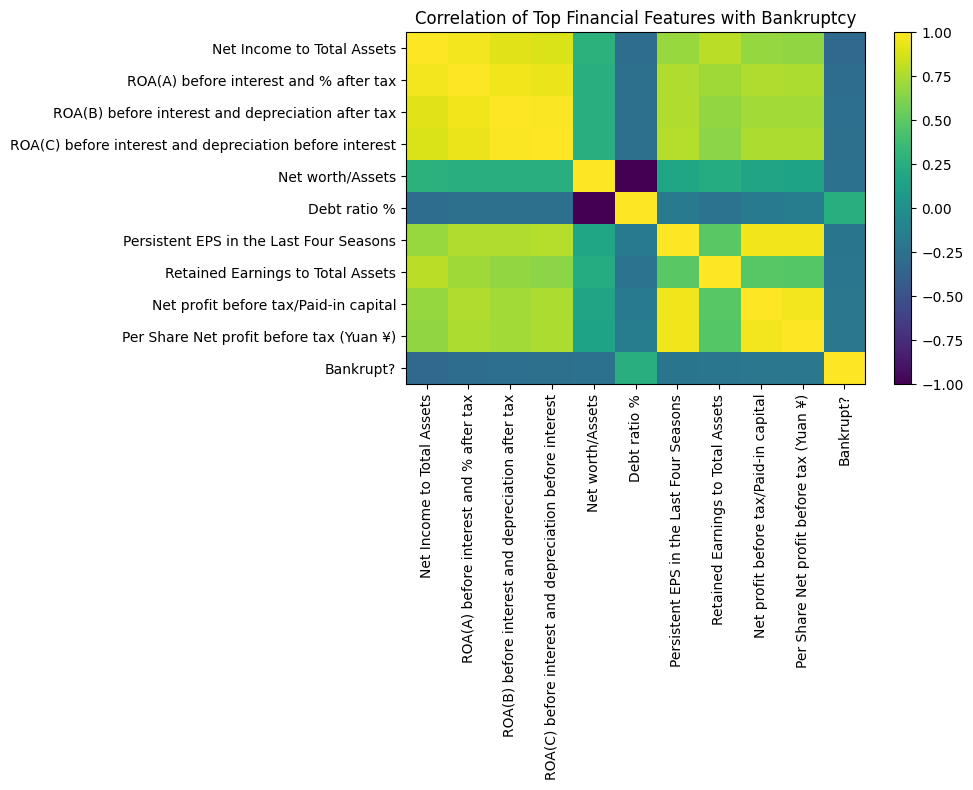

In [ ]:
# Select 10 features with the strongest absolute correlation
top_corr = correlations.drop('Bankrupt?').abs().sort_values(ascending=False).head(10)

top_features = top_corr.index.tolist()

corr_data = df[top_features + ['Bankrupt?']].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_data, aspect='auto')
plt.colorbar()

plt.xticks(range(len(corr_data.columns)), corr_data.columns, rotation=90)
plt.yticks(range(len(corr_data.columns)), corr_data.columns)

plt.title("Correlation of Top Financial Features with Bankruptcy")
plt.tight_layout()
plt.show()

In [ ]:
# Remove leading/trailing spaces from all column names
df.columns = df.columns.str.strip()

print(df.columns[:10].tolist())

['Bankrupt?', 'ROA(C) before interest and depreciation before interest', 'ROA(A) before interest and % after tax', 'ROA(B) before interest and depreciation after tax', 'Operating Gross Margin', 'Realized Sales Gross Margin', 'Operating Profit Rate', 'Pre-tax net Interest Rate', 'After-tax net Interest Rate', 'Non-industry income and expenditure/revenue']


<Figure size 700x500 with 0 Axes>

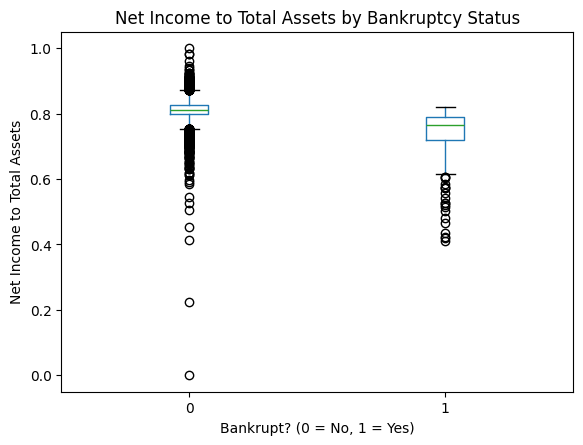

In [ ]:
feature = 'Net Income to Total Assets'

plt.figure(figsize=(7, 5))

df.boxplot(
    column=feature,
    by='Bankrupt?',
    grid=False
)

plt.title(f"{feature} by Bankruptcy Status")
plt.suptitle("")
plt.xlabel("Bankrupt? (0 = No, 1 = Yes)")
plt.ylabel(feature)

plt.show()

<Figure size 700x500 with 0 Axes>

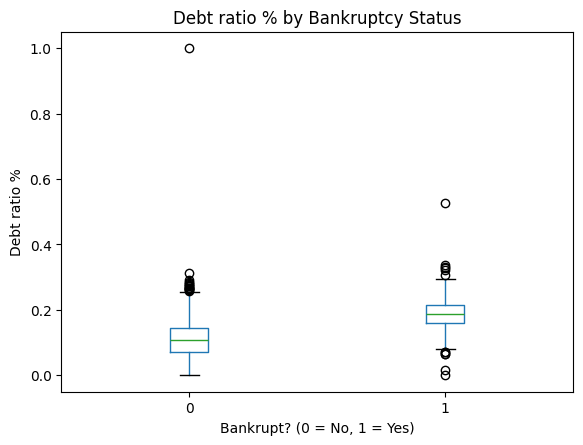

In [ ]:
feature = 'Debt ratio %'

plt.figure(figsize=(7, 5))

df.boxplot(
    column=feature,
    by='Bankrupt?',
    grid=False
)

plt.title(f"{feature} by Bankruptcy Status")
plt.suptitle("")
plt.xlabel("Bankrupt? (0 = No, 1 = Yes)")
plt.ylabel(feature)

plt.show()

In [ ]:
missing = df.isnull().sum()

print("Total missing values:", missing.sum())

display(
    missing[missing > 0]
    .sort_values(ascending=False)
)

Total missing values: 0


,0


## Binning / Discretization

Binning was considered for the continuous financial features. However, it was
not applied because the dataset contains financial ratios, profitability
measures, liquidity measures, leverage measures, and growth rates whose
continuous numerical values contain useful information about the degree of
financial health.

Converting these continuous variables into ranges could result in loss of
information and reduce the model's ability to distinguish between companies
with similar but not identical financial conditions.

Therefore, the original continuous values are retained rather than applying
arbitrary bins.

In [ ]:
X = df.drop(columns=['Bankrupt?'])
y = df['Bankrupt?']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (6819, 94)
Target shape: (6819,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (5455, 94)
Testing data: (1364, 94)
Training target: (5455,)
Testing target: (1364,)


## 8. Class Distribution After Train-Test Split

Since the target variable is highly imbalanced, stratified sampling was
used during the train-test split. The class distribution is checked again
to ensure that both training and testing datasets maintain approximately
the same proportion of bankrupt and non-bankrupt companies.

In [ ]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Bankrupt?
0    96.773602
1     3.226398
Name: proportion, dtype: float64

Testing target distribution:
Bankrupt?
0    96.774194
1     3.225806
Name: proportion, dtype: float64


## 9. Feature Scaling

The financial features have different numerical ranges and scales.
Standardization is applied so that the features are placed on a comparable
scale.

StandardScaler transforms each feature using:

z = (x - mean) / standard deviation

The scaler is fitted only on the training data and then applied to both the
training and testing data. This prevents information from the test set from
leaking into the training process.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (5455, 94)
Scaled testing shape: (1364, 94)


In [ ]:
import numpy as np

print("Mean of scaled training features:")
print(np.mean(X_train_scaled, axis=0))

print("\nStandard deviation of scaled training features:")
print(np.std(X_train_scaled, axis=0))

Mean of scaled training features:
[ 2.47159458e-16  3.52340623e-16  4.42868066e-17  2.53997862e-17
  2.30747288e-15 -7.77493967e-15  1.91345056e-15 -1.62024585e-14
  3.53675740e-15  1.07304327e-14  1.04204251e-17 -9.63889321e-17
 -1.26217399e-15 -9.76914852e-18 -7.68506350e-17  1.32144016e-15
  1.43280845e-17  4.42216790e-16  4.22027216e-16  2.45466139e-15
  2.60510627e-18 -1.81054886e-16 -1.51096164e-16  1.05050910e-15
  4.88717937e-15  7.68506350e-17  3.48660911e-15 -4.33750194e-16
  2.93074456e-17  0.00000000e+00 -1.24784590e-14 -4.05615047e-15
  2.08408502e-17  2.60510627e-18 -2.07626970e-15  3.25638284e-19
  1.57608929e-16 -1.78189269e-15  7.16404225e-18 -5.81589975e-16
 -1.17229782e-17  1.73239567e-16 -4.35704024e-16 -1.93852470e-15
  5.92661677e-17 -5.86148911e-18 -3.90765941e-18  5.21021254e-17
  3.41920198e-17 -2.99587221e-17  6.51276568e-18 -6.79932737e-16
  0.00000000e+00  1.11368293e-15  1.52398717e-16 -3.79694239e-16
 -6.80584014e-17  1.30255314e-18  2.60510627e-18  3.2563

## 10. Feature Selection Using Correlation Filter

The dataset initially contains 94 predictor features. To reduce dimensionality
and remove features with weak relationships with the target, a correlation
filter is applied.

The absolute Pearson correlation between each feature and the bankruptcy
target is calculated using the training data only. Features with an absolute
correlation of at least 0.10 are retained.

Using the training data for feature selection prevents information from the
test set from influencing the preprocessing process.

In [ ]:
# Calculate feature-target correlations using training data only

train_corr = X_train.copy()
train_corr['Bankrupt?'] = y_train

correlations = (
    train_corr.corr()['Bankrupt?']
    .drop('Bankrupt?')
    .abs()
    .sort_values(ascending=False)
)

# Select features with absolute correlation >= 0.10
selected_features = correlations[correlations >= 0.10].index.tolist()

print("Features before selection:", X_train.shape[1])
print("Features after selection:", len(selected_features))

print("\nSelected features:")
for i, feature in enumerate(selected_features, 1):
    print(i, feature)

Features before selection: 94
Features after selection: 29

Selected features:
1 Net Income to Total Assets
2 ROA(A) before interest and % after tax
3 ROA(B) before interest and depreciation after tax
4 ROA(C) before interest and depreciation before interest
5 Net worth/Assets
6 Debt ratio %
7 Persistent EPS in the Last Four Seasons
8 Retained Earnings to Total Assets
9 Net Income to Stockholder's Equity
10 Net profit before tax/Paid-in capital
11 Per Share Net profit before tax (Yuan ¥)
12 Borrowing dependency
13 Current Liability to Assets
14 Working Capital to Total Assets
15 Current Liability to Current Assets
16 Liability to Equity
17 Net Value Per Share (A)
18 Current Liabilities/Equity
19 Current Liability to Equity
20 Net Value Per Share (B)
21 Net Value Per Share (C)
22 Total expense/Assets
23 Operating Profit Per Share (Yuan ¥)
24 Operating profit/Paid-in capital
25 Working Capital/Equity
26 Equity to Long-term Liability
27 CFO to Assets
28 Tax rate (A)
29 Inventory and accou

Feature Selection Result: The dataset initially contained 94 predictor variables. A correlation-based filter was applied using only the training data, retaining features with an absolute Pearson correlation of at least 0.10 with the bankruptcy target. This reduced the feature set from 94 to 29 relevant predictors.

## 11. Model Training

After preprocessing and feature selection, the final dataset contains
29 selected financial features.

The training dataset contains 5,455 companies and the testing dataset
contains 1,364 companies. The training data will be used to build the
classification models, while the testing data will remain unseen until
model evaluation.

In [ ]:
# Apply the selected feature list to the scaled datasets

selected_indices = [X_train.columns.get_loc(feature) for feature in selected_features]

X_train_final = X_train_scaled[:, selected_indices]
X_test_final = X_test_scaled[:, selected_indices]

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (5455, 29)
Final testing shape: (1364, 29)


In [ ]:
print("Training class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())

Training class counts:
Bankrupt?
0    5279
1     176
Name: count, dtype: int64

Testing class counts:
Bankrupt?
0    1320
1      44
Name: count, dtype: int64


## 12. Baseline Model — Logistic Regression

Logistic Regression is used as the baseline classification model because it
is a simple and interpretable algorithm for binary classification.

The model estimates the probability that a company belongs to the bankrupt
class (1) or non-bankrupt class (0).

The model is trained only on the training dataset. The testing dataset is
kept unseen for later evaluation.

In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

logistic_model.fit(X_train_final, y_train)

y_pred_lr = logistic_model.predict(X_test_final)
y_prob_lr = logistic_model.predict_proba(X_test_final)[:, 1]

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


## 15. Logistic Regression Evaluation

The Logistic Regression model is evaluated on the unseen testing dataset.

Because the dataset is highly imbalanced, multiple evaluation metrics are
used instead of relying only on accuracy. Precision, recall, F1-score and
ROC-AUC are considered to evaluate the model's ability to identify both
classes, particularly the minority bankrupt class.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy  : {accuracy_lr:.4f}")
print(f"Precision : {precision_lr:.4f}")
print(f"Recall    : {recall_lr:.4f}")
print(f"F1-Score  : {f1_lr:.4f}")
print(f"ROC-AUC   : {roc_auc_lr:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Results
---------------------------
Accuracy  : 0.8790
Precision : 0.1929
Recall    : 0.8636
F1-Score  : 0.3154
ROC-AUC   : 0.9356

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93      1320
           1       0.19      0.86      0.32        44

    accuracy                           0.88      1364
   macro avg       0.59      0.87      0.62      1364
weighted avg       0.97      0.88      0.91      1364



## 16. Confusion Matrix — Logistic Regression

A confusion matrix is used to examine the types of predictions made by the
Logistic Regression model.

It shows:
- True Negatives (TN): non-bankrupt companies correctly identified
- False Positives (FP): non-bankrupt companies incorrectly classified as bankrupt
- False Negatives (FN): bankrupt companies incorrectly classified as non-bankrupt
- True Positives (TP): bankrupt companies correctly identified

This helps us understand the model's errors beyond the overall evaluation
metrics.

Confusion Matrix:
[[1161  159]
 [   6   38]]


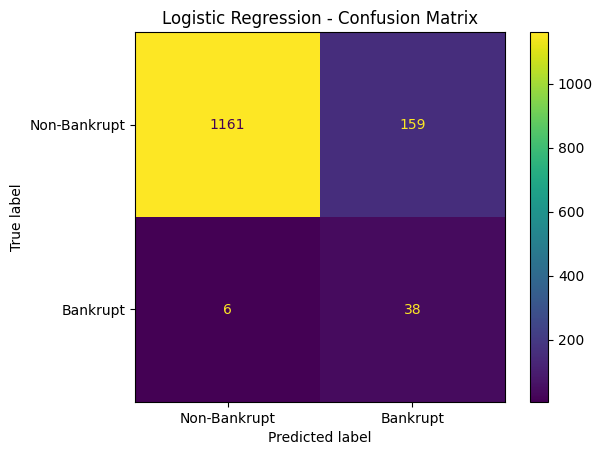

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Bankrupt", "Bankrupt"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [ ]:

# STEP 1: Inspect existing variables

important_vars = [
    "df", "data", "X", "y",
    "X_train", "X_test",
    "y_train", "y_test",
    "X_train_selected", "X_test_selected",
    "X_train_scaled", "X_test_scaled",
    "y_train_resampled", "y_train_balanced",
    "log_reg", "lr_model", "y_pred", "y_prob"
]

print("EXISTING VARIABLES")
print("-" * 45)

for var in important_vars:
    if var in globals():
        obj = globals()[var]

        if hasattr(obj, "shape"):
            print(f"{var}: available | shape = {obj.shape}")
        else:
            print(f"{var}: available | type = {type(obj).__name__}")
    else:
        print(f"{var}: not found")


EXISTING VARIABLES
---------------------------------------------
df: available | shape = (6819, 95)
data: not found
X: available | shape = (6819, 94)
y: available | shape = (6819,)
X_train: available | shape = (5455, 94)
X_test: available | shape = (1364, 94)
y_train: available | shape = (5455,)
y_test: available | shape = (1364,)
X_train_selected: not found
X_test_selected: not found
X_train_scaled: available | shape = (5455, 94)
X_test_scaled: available | shape = (1364, 94)
y_train_resampled: not found
y_train_balanced: not found
log_reg: not found
lr_model: not found
y_pred: not found
y_prob: not found


In [ ]:

# STEP 2: Verify target, split and preprocessing

import numpy as np
import pandas as pd

print("=" * 55)
print("1. TARGET COLUMN CHECK")
print("=" * 55)

print("Target name:", y.name)
print("Target values:", sorted(pd.Series(y).dropna().unique().tolist()))
print("Target column inside X:", y.name in X.columns)

print("\n" + "=" * 55)
print("2. TRAIN / TEST CLASS DISTRIBUTION")
print("=" * 55)

for name, target in [
    ("Full target", y),
    ("Training target", y_train),
    ("Testing target", y_test)
]:
    print(f"\n{name}:")
    print(target.value_counts().sort_index().to_dict())
    print(
        (target.value_counts(normalize=True)
         .sort_index() * 100).round(2).to_dict()
    )

print("\n" + "=" * 55)
print("3. FEATURE COLUMN CHECK")
print("=" * 55)

print("X features:", X.shape[1])
print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

print("Train/test feature columns match:",
      list(X_train.columns) == list(X_test.columns))

print("Missing values in X:", X.isnull().sum().sum())
print("Infinite values in X:",
      np.isinf(X.select_dtypes(include=np.number)).sum().sum())

print("\n" + "=" * 55)
print("4. SCALING CHECK")
print("=" * 55)

print("Original X mean (first 5 features):")
print(X.mean(numeric_only=True).head().round(3))

print("\nScaled training mean (first 5 features):")
print(X_train_scaled.mean(axis=0)[:5].round(3))

print("\nScaled testing mean (first 5 features):")
print(X_test_scaled.mean(axis=0)[:5].round(3))

print("\nNOTE: These checks do not prove whether scaling leaked "
      "test information. We will verify how the scaler was fitted.")


1. TARGET COLUMN CHECK
Target name: Bankrupt?
Target values: [0, 1]
Target column inside X: False

2. TRAIN / TEST CLASS DISTRIBUTION

Full target:
{0: 6599, 1: 220}
{0: 96.77, 1: 3.23}

Training target:
{0: 5279, 1: 176}
{0: 96.77, 1: 3.23}

Testing target:
{0: 1320, 1: 44}
{0: 96.77, 1: 3.23}

3. FEATURE COLUMN CHECK
X features: 94
Training features: 94
Testing features: 94
Train/test feature columns match: True
Missing values in X: 0
Infinite values in X: 0

4. SCALING CHECK
Original X mean (first 5 features):
ROA(C) before interest and depreciation before interest    0.505
ROA(A) before interest and % after tax                     0.559
ROA(B) before interest and depreciation after tax          0.554
Operating Gross Margin                                     0.608
Realized Sales Gross Margin                                0.608
dtype: float64

Scaled training mean (first 5 features):
[0. 0. 0. 0. 0.]

Scaled testing mean (first 5 features):
[0.061 0.062 0.052 0.054 0.055]

NOTE: Th

In [ ]:

# STEP 2B: Inspect existing preprocessing objects

print("SCALER OBJECTS")
print("-" * 45)

scaler_found = False

for name, obj in list(globals().items()):
    if any(word in name.lower() for word in ["scaler", "standard", "normalizer", "minmax"]):
        if hasattr(obj, "mean_") or hasattr(obj, "scale_") or hasattr(obj, "data_min_"):
            scaler_found = True
            print(f"\n{name}: {type(obj).__name__}")

            if hasattr(obj, "n_features_in_"):
                print("Features fitted:", obj.n_features_in_)

            if hasattr(obj, "n_samples_seen_"):
                print("Samples seen during fit:", obj.n_samples_seen_)

            if hasattr(obj, "feature_names_in_"):
                print("Feature names recorded:",
                      len(obj.feature_names_in_))

if not scaler_found:
    print("No fitted scaler object found under common names.")

print("\nFEATURE SELECTION OBJECTS")
print("-" * 45)

selector_found = False

for name, obj in list(globals().items()):
    if any(word in name.lower() for word in
           ["selector", "selectkbest", "rfe", "selected_features"]):
        selector_found = True
        print(f"{name}: {type(obj).__name__}")

        if hasattr(obj, "get_support"):
            print("Selected features:",
                  int(obj.get_support().sum()))

if not selector_found:
    print("No obvious feature-selection object found.")

print("\nCurrent train/test shapes:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled :", X_test_scaled.shape)


SCALER OBJECTS
---------------------------------------------

scaler: StandardScaler
Features fitted: 94
Samples seen during fit: 5455
Feature names recorded: 94

FEATURE SELECTION OBJECTS
---------------------------------------------
selected_features: list
selector_found: bool

Current train/test shapes:
X_train: (5455, 94)
X_test : (1364, 94)
X_train_scaled: (5455, 94)
X_test_scaled : (1364, 94)


In [ ]:

# STEP 2C: Inspect selected feature names

print("SELECTED FEATURES AUDIT")
print("-" * 45)

print("Type:", type(selected_features).__name__)
print("Number of selected features:", len(selected_features))
print("\nSelected feature names:")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

print("\nAre all selected features in X?",
      all(feature in X.columns for feature in selected_features))

print("\nAny duplicate feature names?",
      len(selected_features) != len(set(selected_features)))

print("\nTarget accidentally selected?",
      y.name in selected_features)


SELECTED FEATURES AUDIT
---------------------------------------------
Type: list
Number of selected features: 29

Selected feature names:
1. Net Income to Total Assets
2. ROA(A) before interest and % after tax
3. ROA(B) before interest and depreciation after tax
4. ROA(C) before interest and depreciation before interest
5. Net worth/Assets
6. Debt ratio %
7. Persistent EPS in the Last Four Seasons
8. Retained Earnings to Total Assets
9. Net Income to Stockholder's Equity
10. Net profit before tax/Paid-in capital
11. Per Share Net profit before tax (Yuan ¥)
12. Borrowing dependency
13. Current Liability to Assets
14. Working Capital to Total Assets
15. Current Liability to Current Assets
16. Liability to Equity
17. Net Value Per Share (A)
18. Current Liabilities/Equity
19. Current Liability to Equity
20. Net Value Per Share (B)
21. Net Value Per Share (C)
22. Total expense/Assets
23. Operating Profit Per Share (Yuan ¥)
24. Operating profit/Paid-in capital
25. Working Capital/Equity
26. 

In [ ]:

# STEP 2D: Leakage-safe feature selection

import pandas as pd
from sklearn.preprocessing import StandardScaler

# Use training data only to rank features by correlation with bankruptcy
train_for_selection = X_train.copy()
train_for_selection["Bankrupt?"] = y_train

correlations = (
    train_for_selection.corr(numeric_only=True)["Bankrupt?"]
    .drop("Bankrupt?")
    .abs()
    .sort_values(ascending=False)
)

# Keep features meeting the same 0.10 correlation threshold
selected_features_safe = correlations[correlations >= 0.10].index.tolist()

print("Features selected using training data only:",
      len(selected_features_safe))
print("\nTop 10 features by absolute correlation:")
print(correlations.head(10).round(4))

# Build selected training and test sets
X_train_selected = X_train[selected_features_safe].copy()
X_test_selected = X_test[selected_features_safe].copy()

# Fit scaler on training data only
scaler_selected = StandardScaler()
X_train_selected_scaled = scaler_selected.fit_transform(X_train_selected)
X_test_selected_scaled = scaler_selected.transform(X_test_selected)

print("\nFinal shapes:")
print("X_train_selected:", X_train_selected.shape)
print("X_test_selected:", X_test_selected.shape)
print("X_train_selected_scaled:", X_train_selected_scaled.shape)
print("X_test_selected_scaled:", X_test_selected_scaled.shape)

print("\nTarget leakage:", "Bankrupt?" in selected_features_safe)
print("Train/test feature names match:",
      list(X_train_selected.columns) == list(X_test_selected.columns))


Features selected using training data only: 29

Top 10 features by absolute correlation:
Net Income to Total Assets                                 0.3164
ROA(A) before interest and % after tax                     0.2838
ROA(B) before interest and depreciation after tax          0.2752
ROA(C) before interest and depreciation before interest    0.2627
Net worth/Assets                                           0.2476
Debt ratio %                                               0.2476
Persistent EPS in the Last Four Seasons                    0.2210
Retained Earnings to Total Assets                          0.2138
Net Income to Stockholder's Equity                         0.2066
Net profit before tax/Paid-in capital                      0.2063
Name: Bankrupt?, dtype: float64

Final shapes:
X_train_selected: (5455, 29)
X_test_selected: (1364, 29)
X_train_selected_scaled: (5455, 29)
X_test_selected_scaled: (1364, 29)

Target leakage: False
Train/test feature names match: True


In [ ]:

# STEP 3: Record the reported baseline

baseline_results = pd.DataFrame([{
    "Model": "Logistic Regression (previous run)",
    "Accuracy": 0.8790,
    "Precision": 0.1929,
    "Recall": 0.8636,
    "F1-score": 0.3154,
    "ROC-AUC": 0.9356
}])

print("PREVIOUSLY REPORTED BASELINE")
display(baseline_results)

print("\nCurrent data ready for fair model comparison:")
print("Training rows:", X_train_selected.shape[0])
print("Test rows:", X_test_selected.shape[0])
print("Selected features:", X_train_selected.shape[1])
print("Training bankrupt cases:", int((y_train == 1).sum()))
print("Test bankrupt cases:", int((y_test == 1).sum()))


PREVIOUSLY REPORTED BASELINE


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression (previous run),0.879,0.1929,0.8636,0.3154,0.9356



Current data ready for fair model comparison:
Training rows: 5455
Test rows: 1364
Selected features: 29
Training bankrupt cases: 176
Test bankrupt cases: 44


In [ ]:

# STEP 3: Train a fair Logistic Regression baseline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)
import pandas as pd

# Train on the selected, scaled training data
baseline_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

baseline_model.fit(X_train_selected_scaled, y_train)

# Predictions on the held-out test set
baseline_pred = baseline_model.predict(X_test_selected_scaled)
baseline_prob = baseline_model.predict_proba(X_test_selected_scaled)[:, 1]

# Calculate evaluation metrics
baseline_metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1-score": f1_score(y_test, baseline_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_prob),
    "PR-AUC": average_precision_score(y_test, baseline_prob)
}

baseline_results_fair = pd.DataFrame([baseline_metrics])

print("FAIR BASELINE RESULTS")
display(baseline_results_fair.round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, baseline_pred, zero_division=0))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, baseline_pred))
print("\nRows = actual class; columns = predicted class.")


FAIR BASELINE RESULTS


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.9721,0.6875,0.25,0.3667,0.9316,0.4441



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1320
           1       0.69      0.25      0.37        44

    accuracy                           0.97      1364
   macro avg       0.83      0.62      0.68      1364
weighted avg       0.97      0.97      0.97      1364

CONFUSION MATRIX
[[1315    5]
 [  33   11]]

Rows = actual class; columns = predicted class.


In [ ]:

# STEP 4: Prepare XGBoost

%pip -q install xgboost

import xgboost as xgb
from sklearn.utils.class_weight import compute_class_weight

# Calculate imbalance ratio using training labels only
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

scale_pos_weight = negative_count / positive_count

print("XGBoost version:", xgb.__version__)
print("\nTraining class counts:")
print("Non-bankrupt (0):", negative_count)
print("Bankrupt (1):", positive_count)
print("Negative / positive ratio:", round(scale_pos_weight, 2))
print("\nSelected feature count:", X_train_selected.shape[1])
print("Training shape:", X_train_selected.shape)
print("Testing shape:", X_test_selected.shape)

print("\nXGBoost setup is ready.")


XGBoost version: 3.4.1

Training class counts:
Non-bankrupt (0): 5279
Bankrupt (1): 176
Negative / positive ratio: 29.99

Selected feature count: 29
Training shape: (5455, 29)
Testing shape: (1364, 29)

XGBoost setup is ready.


In [ ]:

# STEP 5: Train the XGBoost classifier

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=400,
    max_depth=3,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_selected, y_train)

print("XGBoost training completed successfully!")
print("Training samples:", X_train_selected.shape[0])
print("Features used:", X_train_selected.shape[1])
print("Trees configured:", xgb_model.n_estimators)
print("Positive-class weight:", xgb_model.scale_pos_weight)


XGBoost training completed successfully!
Training samples: 5455
Features used: 29
Trees configured: 400
Positive-class weight: 29.994318181818183


In [ ]:

# STEP 6: Evaluate XGBoost

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)
import pandas as pd

# Predict class labels and bankruptcy probabilities
xgb_pred = xgb_model.predict(X_test_selected)
xgb_prob = xgb_model.predict_proba(X_test_selected)[:, 1]

# Calculate metrics
xgb_metrics = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred, zero_division=0),
    "Recall": recall_score(y_test, xgb_pred, zero_division=0),
    "F1-score": f1_score(y_test, xgb_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, xgb_prob),
    "PR-AUC": average_precision_score(y_test, xgb_prob)
}

xgb_results = pd.DataFrame([xgb_metrics])

print("XGBOOST RESULTS")
display(xgb_results.round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, xgb_pred, zero_division=0))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, xgb_pred))
print("\nRows = actual class; columns = predicted class.")


XGBOOST RESULTS


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,XGBoost,0.9362,0.2991,0.7273,0.4238,0.9272,0.4244



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      0.94      0.97      1320
           1       0.30      0.73      0.42        44

    accuracy                           0.94      1364
   macro avg       0.64      0.84      0.70      1364
weighted avg       0.97      0.94      0.95      1364

CONFUSION MATRIX
[[1245   75]
 [  12   32]]

Rows = actual class; columns = predicted class.


In [ ]:

# STEP 7: Tune the XGBoost classification threshold
# Validation data comes only from the original training set.

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score
)
from xgboost import XGBClassifier

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_selected,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

val_weight = (y_subtrain == 0).sum() / (y_subtrain == 1).sum()

xgb_tuning_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=400,
    max_depth=3,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2,
    scale_pos_weight=val_weight,
    random_state=42,
    n_jobs=-1
)

xgb_tuning_model.fit(X_subtrain, y_subtrain)

val_prob = xgb_tuning_model.predict_proba(X_val)[:, 1]

threshold_rows = []

for threshold in np.arange(0.10, 0.91, 0.05):
    val_pred = (val_prob >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_rows)

print("VALIDATION PR-AUC:", round(
    average_precision_score(y_val, val_prob), 4
))

print("\nTHRESHOLD COMPARISON")
display(threshold_results.round(4))

best_row = threshold_results.loc[
    threshold_results["F1-score"].idxmax()
]

print("\nBest validation threshold by F1-score:",
      best_row["Threshold"])
print("Validation precision:", round(best_row["Precision"], 4))
print("Validation recall:", round(best_row["Recall"], 4))
print("Validation F1-score:", round(best_row["F1-score"], 4))


VALIDATION PR-AUC: 0.3617

THRESHOLD COMPARISON


,Threshold,Precision,Recall,F1-score
0,0.10,0.1899,0.8571,0.3109
1,0.15,0.2117,0.8286,0.3372
2,0.20,0.2231,0.7714,0.3462
3,0.25,0.2342,0.7429,0.3562
4,0.30,0.2551,0.7143,0.3759
5,0.35,0.2660,0.7143,0.3876
6,0.40,0.2791,0.6857,0.3967
7,0.45,0.2785,0.6286,0.3860
8,0.50,0.2917,0.6000,0.3925
9,0.55,0.2727,0.5143,0.3564



Best validation threshold by F1-score: 0.4
Validation precision: 0.2791
Validation recall: 0.6857
Validation F1-score: 0.3967


In [ ]:

# STEP 7B: Final test evaluation at the validation-selected threshold

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)

chosen_threshold = 0.40

# Use the tuning model trained on the training subset
test_prob_tuned = xgb_tuning_model.predict_proba(
    X_test_selected
)[:, 1]

test_pred_tuned = (
    test_prob_tuned >= chosen_threshold
).astype(int)

tuned_test_results = {
    "Model": "XGBoost (threshold 0.40)",
    "Threshold": chosen_threshold,
    "Accuracy": accuracy_score(y_test, test_pred_tuned),
    "Precision": precision_score(
        y_test, test_pred_tuned, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_pred_tuned, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, test_pred_tuned, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, test_prob_tuned),
    "PR-AUC": average_precision_score(y_test, test_prob_tuned)
}

print("TUNED XGBOOST — HELD-OUT TEST RESULTS")
display(pd.DataFrame([tuned_test_results]).round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, test_pred_tuned, zero_division=0
))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, test_pred_tuned))
print("\nRows = actual class; columns = predicted class.")


TUNED XGBOOST — HELD-OUT TEST RESULTS


,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,XGBoost (threshold 0.40),0.4,0.9311,0.2727,0.6818,0.3896,0.9252,0.4507



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      1320
           1       0.27      0.68      0.39        44

    accuracy                           0.93      1364
   macro avg       0.63      0.81      0.68      1364
weighted avg       0.97      0.93      0.94      1364

CONFUSION MATRIX
[[1240   80]
 [  14   30]]

Rows = actual class; columns = predicted class.


In [ ]:

# STEP 8: Check whether the dataset supports genuine sequences

print("DATASET COLUMNS")
print("-" * 45)

for col in df.columns:
    print(col)

print("\nPOSSIBLE IDENTIFIER / TIME COLUMNS")
print("-" * 45)

keywords = [
    "company", "firm", "stock", "id", "year",
    "date", "time", "period", "quarter", "month"
]

possible_cols = [
    col for col in df.columns
    if any(word in col.lower() for word in keywords)
]

print(possible_cols if possible_cols else
      "No obvious identifier or time columns found.")

print("\nDATASET SHAPE:", df.shape)


DATASET COLUMNS
---------------------------------------------
Bankrupt?
ROA(C) before interest and depreciation before interest
ROA(A) before interest and % after tax
ROA(B) before interest and depreciation after tax
Operating Gross Margin
Realized Sales Gross Margin
Operating Profit Rate
Pre-tax net Interest Rate
After-tax net Interest Rate
Non-industry income and expenditure/revenue
Continuous interest rate (after tax)
Operating Expense Rate
Research and development expense rate
Cash flow rate
Interest-bearing debt interest rate
Tax rate (A)
Net Value Per Share (B)
Net Value Per Share (A)
Net Value Per Share (C)
Persistent EPS in the Last Four Seasons
Cash Flow Per Share
Revenue Per Share (Yuan ¥)
Operating Profit Per Share (Yuan ¥)
Per Share Net profit before tax (Yuan ¥)
Realized Sales Gross Profit Growth Rate
Operating Profit Growth Rate
After-tax Net Profit Growth Rate
Regular Net Profit Growth Rate
Continuous Net Profit Growth Rate
Total Asset Growth Rate
Net Value Growth Rate
T

In [ ]:

# STEP 8B: Prepare selected financial features for an LSTM

import numpy as np

# Use the training-fitted scaler from our leakage-safe pipeline
X_train_lstm = np.asarray(
    X_train_selected_scaled, dtype=np.float32
).reshape(-1, len(selected_features_safe), 1)

X_test_lstm = np.asarray(
    X_test_selected_scaled, dtype=np.float32
).reshape(-1, len(selected_features_safe), 1)

y_train_lstm = np.asarray(y_train, dtype=np.float32)
y_test_lstm = np.asarray(y_test, dtype=np.float32)

print("LSTM input preparation complete")
print("Training input shape:", X_train_lstm.shape)
print("Testing input shape:", X_test_lstm.shape)
print("Training labels shape:", y_train_lstm.shape)
print("Testing labels shape:", y_test_lstm.shape)
print("\nSequence positions per company:", X_train_lstm.shape[1])
print("Features per sequence position:", X_train_lstm.shape[2])
print("\nCaution: sequence positions represent financial features,")
print("not chronological observations.")


LSTM input preparation complete
Training input shape: (5455, 29, 1)
Testing input shape: (1364, 29, 1)
Training labels shape: (5455,)
Testing labels shape: (1364,)

Sequence positions per company: 29
Features per sequence position: 1

Caution: sequence positions represent financial features,
not chronological observations.


In [ ]:

# STEP 9: Build and train an experimental LSTM

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

# Split training data for validation; test set remains untouched
X_lstm_train, X_lstm_val, y_lstm_train, y_lstm_val = train_test_split(
    X_train_lstm,
    y_train_lstm,
    test_size=0.20,
    stratify=y_train_lstm,
    random_state=42
)

# Calculate class weights from the LSTM training subset only
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_lstm_train.astype(int)
)
lstm_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

lstm_model = Sequential([
    Input(shape=(X_train_lstm.shape[1], 1)),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

history = lstm_model.fit(
    X_lstm_train,
    y_lstm_train,
    validation_data=(X_lstm_val, y_lstm_val),
    epochs=30,
    batch_size=64,
    class_weight=lstm_class_weights,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

print("\nLSTM training completed!")
print("Training subset:", X_lstm_train.shape)
print("Validation subset:", X_lstm_val.shape)
print("Class weights:", lstm_class_weights)
print("Epochs completed:", len(history.history["loss"]))


Epoch 1/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.6366 - precision: 0.0565 - recall: 0.7518 - val_loss: 0.5576 - val_precision: 0.0942 - val_recall: 0.8286
Epoch 2/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.5199 - precision: 0.0897 - recall: 0.8014 - val_loss: 0.5074 - val_precision: 0.0926 - val_recall: 0.8571
Epoch 3/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.5044 - precision: 0.0944 - recall: 0.8227 - val_loss: 0.4550 - val_precision: 0.1091 - val_recall: 0.8571
Epoch 4/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.4680 - precision: 0.1028 - recall: 0.8085 - val_loss: 0.5503 - val_precision: 0.0994 - val_recall: 0.8857
Epoch 5/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.4675 - precision: 0.0932 - recall: 0.8440 - val_loss: 0.3610 - val_precision: 0.1261 - val_recall: 0.8000
Epoch 6/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.4590 - precision: 0.0953 - recall: 0.8511 - val_loss: 0.4405 - val_precision: 0.1017 - val_recall: 0.857

In [ ]:

# STEP 9B: Evaluate LSTM on the held-out test set

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)

# Predicted bankruptcy probabilities
lstm_prob = lstm_model.predict(X_test_lstm, verbose=0).ravel()

# Default classification threshold
lstm_threshold = 0.50
lstm_pred = (lstm_prob >= lstm_threshold).astype(int)

# Calculate metrics
lstm_metrics = {
    "Model": "LSTM (feature-sequence experiment)",
    "Accuracy": accuracy_score(y_test_lstm, lstm_pred),
    "Precision": precision_score(
        y_test_lstm, lstm_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test_lstm, lstm_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_test_lstm, lstm_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test_lstm, lstm_prob),
    "PR-AUC": average_precision_score(y_test_lstm, lstm_prob)
}

print("LSTM TEST RESULTS")
display(pd.DataFrame([lstm_metrics]).round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_lstm, lstm_pred, zero_division=0
))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test_lstm, lstm_pred))
print("\nRows = actual class; columns = predicted class.")


LSTM TEST RESULTS


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,LSTM (feature-sequence experiment),0.8182,0.1304,0.8182,0.225,0.8987,0.3084



CLASSIFICATION REPORT
              precision    recall  f1-score   support

         0.0       0.99      0.82      0.90      1320
         1.0       0.13      0.82      0.23        44

    accuracy                           0.82      1364
   macro avg       0.56      0.82      0.56      1364
weighted avg       0.96      0.82      0.88      1364

CONFUSION MATRIX
[[1080  240]
 [   8   36]]

Rows = actual class; columns = predicted class.


In [ ]:

# STEP 10: Prepare and build an experimental Transformer

import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

# Split the original training data for validation
X_transformer_train, X_transformer_val, y_transformer_train, y_transformer_val = train_test_split(
    X_train_selected_scaled.astype(np.float32),
    np.asarray(y_train, dtype=np.float32),
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

# Reshape each row into 29 feature tokens with one value each
X_transformer_train = X_transformer_train[..., np.newaxis]
X_transformer_val = X_transformer_val[..., np.newaxis]
X_transformer_test = X_test_selected_scaled.astype(np.float32)[..., np.newaxis]

# Class weights from the training subset only
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_transformer_train.astype(int)
)
transformer_class_weights = {
    int(c): float(w) for c, w in zip(classes, weights)
}

# Small Transformer encoder
inputs = layers.Input(shape=(29, 1))

x = layers.Dense(32)(inputs)

attention = layers.MultiHeadAttention(
    num_heads=4,
    key_dim=8,
    dropout=0.1
)(x, x)

x = layers.Add()([x, attention])
x = layers.LayerNormalization()(x)

ffn = layers.Dense(64, activation="relu")(x)
ffn = layers.Dropout(0.2)(ffn)
ffn = layers.Dense(32)(ffn)

x = layers.Add()([x, ffn])
x = layers.LayerNormalization()(x)

x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(16, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

transformer_model = Model(inputs, outputs)

transformer_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Transformer architecture built successfully!")
print("Training shape:", X_transformer_train.shape)
print("Validation shape:", X_transformer_val.shape)
print("Test shape:", X_transformer_test.shape)
print("Class weights:", transformer_class_weights)

transformer_model.summary()


Transformer architecture built successfully!
Training shape: (4364, 29, 1)
Validation shape: (1091, 29, 1)
Test shape: (1364, 29, 1)
Class weights: {0: 0.5166942931565238, 1: 15.47517730496454}


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 29, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 29, 32)    │         64 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 29, 32)    │      4,224 │ dense_2[0][0],    │
│ (MultiHeadAttentio… │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 29, 32)    │          0 │ dense_2[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 29, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 29, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 29, 64)    │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 29, 32)    │      2,080 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 29, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 29, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 16)        │        528 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 16)        │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         17 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,153 (35.75 KB)

 Trainable params: 9,153 (35.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# STEP 11: Train the Transformer model

from tensorflow.keras.callbacks import EarlyStopping

early_stop_transformer = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

transformer_history = transformer_model.fit(
    X_transformer_train,
    y_transformer_train,
    validation_data=(X_transformer_val, y_transformer_val),
    epochs=30,
    batch_size=64,
    class_weight=transformer_class_weights,
    callbacks=[early_stop_transformer],
    verbose=1
)

print("\nTransformer training completed!")
print("Epochs actually run:", len(transformer_history.history["loss"]))
print("Best validation loss:", min(transformer_history.history["val_loss"]))


Epoch 1/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 15s 73ms/step - loss: 0.5717 - precision: 0.0771 - recall: 0.7305 - val_loss: 0.5058 - val_precision: 0.0939 - val_recall: 0.8286
Epoch 2/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - loss: 0.5222 - precision: 0.0931 - recall: 0.7801 - val_loss: 0.4856 - val_precision: 0.0989 - val_recall: 0.8000
Epoch 3/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - loss: 0.4783 - precision: 0.1162 - recall: 0.7943 - val_loss: 0.4889 - val_precision: 0.1120 - val_recall: 0.8286
Epoch 4/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - loss: 0.4523 - precision: 0.1218 - recall: 0.7872 - val_loss: 0.5253 - val_precision: 0.1018 - val_recall: 0.8286
Epoch 5/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.4560 - precision: 0.1296 - recall: 0.7730 - val_loss: 0.4380 - val_precision: 0.1349 - val_recall: 0.8286
Epoch 6/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - loss: 0.4521 - precision: 0.1208 - recall: 0.7589 - val_loss: 0.3910 - val_precision: 0.1429 - val_recall: 0.80

In [ ]:

# STEP 12: Evaluate Transformer on the test set

import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

# Predicted probabilities for bankruptcy (class 1)
transformer_probs = transformer_model.predict(
    X_transformer_test, verbose=0
).ravel()

# Default decision threshold
transformer_preds = (transformer_probs >= 0.5).astype(int)

print("TRANSFORMER TEST RESULTS")
print("-" * 35)
print("Accuracy :", round(accuracy_score(y_test, transformer_preds), 4))
print("Precision:", round(precision_score(y_test, transformer_preds, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, transformer_preds, zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, transformer_preds, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, transformer_probs), 4))
print("PR-AUC   :", round(average_precision_score(y_test, transformer_probs), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, transformer_preds))

print("\nClassification Report:")
print(classification_report(
    y_test, transformer_preds,
    target_names=["Not Bankrupt", "Bankrupt"],
    zero_division=0
))


TRANSFORMER TEST RESULTS
-----------------------------------
Accuracy : 0.857
Precision: 0.1614
Recall   : 0.8182
F1-Score : 0.2697
ROC-AUC  : 0.9134
PR-AUC   : 0.3843

Confusion Matrix:
[[1133  187]
 [   8   36]]

Classification Report:
              precision    recall  f1-score   support

Not Bankrupt       0.99      0.86      0.92      1320
    Bankrupt       0.16      0.82      0.27        44

    accuracy                           0.86      1364
   macro avg       0.58      0.84      0.60      1364
weighted avg       0.97      0.86      0.90      1364



In [ ]:

%pip install -q shap

import shap
print("SHAP version:", shap.__version__)
print("XGBoost model available:", "xgb_model" in globals())
print("Selected features:", len(selected_features_safe))


SHAP version: 0.54.1
XGBoost model available: True
Selected features: 29


SHAP

SHAP calculation completed!
Rows explained: 300
Features explained: 29

Top 10 most influential features:
                                                Feature  Mean_Absolute_SHAP
                                   Borrowing dependency            1.286196
                Persistent EPS in the Last Four Seasons            0.889660
                      Retained Earnings to Total Assets            0.620631
      ROA(B) before interest and depreciation after tax            0.581832
                                       Net worth/Assets            0.571840
ROA(C) before interest and depreciation before interest            0.542553
                             Net Income to Total Assets            0.426425
                                Net Value Per Share (A)            0.328600
                 ROA(A) before interest and % after tax            0.322424
                            Current Liability to Assets            0.321851


/tmp/ipykernel_521/2006559978.py:31: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_shap, max_display=8)


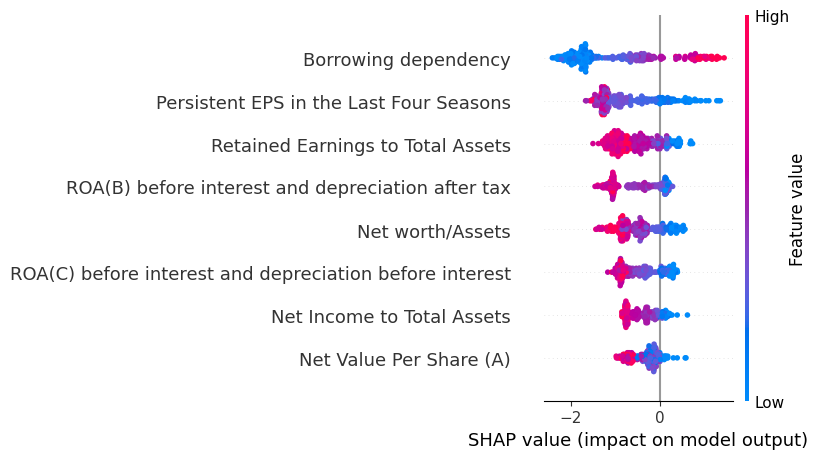

In [ ]:

# STEP 14A: Calculate SHAP values for XGBoost

import shap
import pandas as pd
import matplotlib.pyplot as plt

# Use a sample of the test data to keep computation manageable
X_shap = X_test_selected.sample(
    n=min(300, len(X_test_selected)),
    random_state=42
)

# Explain the trained XGBoost model
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap)

print("SHAP calculation completed!")
print("Rows explained:", X_shap.shape[0])
print("Features explained:", X_shap.shape[1])

# Global feature importance
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": abs(shap_values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

print("\nTop 10 most influential features:")
print(shap_importance.head(10).to_string(index=False))

# SHAP summary plot
shap.summary_plot(shap_values, X_shap, max_display=8)


LIME

In [ ]:
# STEP 14B: Explain one prediction using LIME

%pip install -q lime

import numpy as np
import pandas as pd
from lime.lime_tabular import LimeTabularExplainer

feature_names = list(X_train_selected.columns)

# Train the explainer using training data only
lime_explainer = LimeTabularExplainer(
    training_data=X_train_selected.to_numpy(),
    feature_names=feature_names,
    class_names=["Not Bankrupt", "Bankrupt"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Choose a genuinely bankrupt company from the test set, if available
test_labels = np.asarray(y_test).astype(int)
bankrupt_positions = np.flatnonzero(test_labels == 1)

if len(bankrupt_positions) == 0:
    raise ValueError("No bankrupt examples found in the test set.")

idx = int(bankrupt_positions[0])
company_row = X_test_selected.iloc[idx].to_numpy()

# Convert LIME's NumPy inputs back to the expected feature columns
def lime_predict_fn(data):
    data_df = pd.DataFrame(data, columns=feature_names)
    return xgb_model.predict_proba(data_df)

explanation = lime_explainer.explain_instance(
    data_row=company_row,
    predict_fn=lime_predict_fn,
    num_features=10,
    labels=[1]
)

print("Actual label:", "Bankrupt" if test_labels[idx] == 1 else "Not Bankrupt")
print("XGBoost predicted probability of bankruptcy:",
      round(float(lime_predict_fn(company_row.reshape(1, -1))[0, 1]), 4))

print("\nLIME explanation for the Bankrupt class:")
for feature, weight in explanation.as_list(label=1):
    print(f"{feature}: {weight:.4f}")

from IPython.display import display, HTML

display(HTML("""
<style>
.lime {
    background-color: white !important;
    color: black !important;
}
.lime table, .lime tr, .lime td, .lime th {
    background-color: white !important;
    color: black !important;
}
</style>
"""))

explanation.show_in_notebook(show_table=True)




  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Actual label: Bankrupt
XGBoost predicted probability of bankruptcy: 0.8854

LIME explanation for the Bankrupt class:
Borrowing dependency > 0.38: 0.0550
Persistent EPS in the Last Four Seasons <= 0.21: 0.0259
ROA(B) before interest and depreciation after tax <= 0.53: 0.0249
ROA(C) before interest and depreciation before interest <= 0.48: 0.0216
Net worth/Assets <= 0.85: 0.0210
Net Income to Total Assets <= 0.80: 0.0171
Retained Earnings to Total Assets <= 0.93: 0.0167
ROA(A) before interest and % after tax <= 0.54: -0.0145
Net Income to Stockholder's Equity <= 0.84: 0.0111
Net Value Per Share (A) <= 0.17: 0.0102


# CREATE LLM REPORT

In [ ]:
# STEP 15: Generate an AI-written SHAP + LIME report

%pip install -q google-genai

from google import genai
from google.colab import userdata
from IPython.display import display, Markdown

# Get the API key from Colab Secrets
# Secret name must be exactly GEMINI_API_KEY
client = genai.Client(
    api_key=userdata.get("GEMINI_API_KEY")
)

# Use the SHAP results already created in STEP 14A
top_shap = shap_importance.head(10).to_string(index=False)

# Use the LIME explanation already created in STEP 14B
lime_results = explanation.as_list(label=1)

# Get the predicted bankruptcy probability for the same company
bankruptcy_probability = float(
    lime_predict_fn(company_row.reshape(1, -1))[0, 1]
)

actual_label = (
    "Bankrupt" if test_labels[idx] == 1 else "Not Bankrupt"
)

# Give Gemini the actual project results

prompt = f"""
Write a detailed but easy-to-understand report for my
Bankruptcy Prediction Project, focusing on how SHAP and LIME
help us understand the predictions made by our machine learning model.

IMPORTANT WRITING INSTRUCTIONS:
- Write for a general audience, including people who have
  no knowledge of Artificial Intelligence or Machine Learning.
- Use simple, everyday English.
- Avoid complicated technical terms. Whenever a technical
  term is necessary, explain what it means in simple words.
- Write in a natural, human-friendly and professional style.
- Explain concepts as if you are introducing them to someone
  who is learning about this topic for the first time.
- Use relatable examples wherever they help understanding.
- Do not make the report sound like a technical research paper.
- Use complete paragraphs and meaningful headings.
- Make the report informative, detailed and easy to read.
- Do not simply list technical definitions. Explain what they
  mean and why they matter in our project.

PROJECT RESULTS:

SHAP results (top 10 features, ranked by mean absolute SHAP):
{top_shap}

LIME explanation for one test company:
Actual label: {actual_label}
Predicted bankruptcy probability: {bankruptcy_probability:.4f}
LIME contributions:
{lime_results}

WRITE THE REPORT USING THESE SECTIONS:

1. Introduction to Explainable AI
Explain what Explainable AI means and why it is important.
Start by explaining that our project predicts whether a company
may go bankrupt or remain financially stable.
Explain why simply receiving a prediction from a computer
is not enough. People should also understand why the model
made that prediction.

2. Understanding SHAP Results
First explain SHAP in very simple language.
Use an everyday example to explain how different financial
factors can influence a prediction.
Then discuss the top 10 features from our actual SHAP results.
Explain what the ranking tells us about which features had
the greatest influence on the model's predictions overall.
Make the explanation understandable even to a non-technical reader.

3. Understanding LIME Results
Explain LIME in simple language.
Describe how it helps us understand the prediction for one
particular company rather than the entire dataset.
Explain the actual test company's prediction using the
provided results.
Clearly explain:
- Positive LIME weights support the Bankrupt prediction.
- Negative LIME weights support the Not Bankrupt prediction.
- LIME weights are contribution values, NOT probability
  percentages.
Explain the contributions using the actual values provided.
Do not invent any additional information.

4. Difference Between SHAP and LIME
Explain their differences using a simple comparison.
SHAP helps us understand which factors generally influence
the model across many companies.
LIME helps us understand why the model made a prediction
for one particular company.
Include a simple real-world analogy to make the difference clear.

5. Limitations of SHAP and LIME
Explain that these methods help us understand the model,
but they do not guarantee that every prediction is correct.
Mention that the explanations show how the model uses
information, not proof that a financial factor causes bankruptcy.
Also explain that the results depend on the quality of
the dataset and the prediction model.

6. Conclusion
Summarise how SHAP and LIME make our bankruptcy prediction
project easier to understand.
Emphasise that Explainable AI helps people gain more insight
into predictions instead of blindly trusting a computer.

STRICT RULES:
- Use ONLY the results provided above.
- Do not invent financial figures, feature values or findings.
- Do not claim that any feature directly causes bankruptcy.
- Do not confuse SHAP feature importance with positive or
  negative influence.
- Do not describe LIME weights as percentages.
- Explain all technical concepts in simple language.
- Ensure the final report flows naturally from introduction
  to conclusion.
- The report should be suitable for submission to a college
  professor and understandable to someone without a technical
  background.

The final output should look like a properly written project
report, not a collection of short answers.
"""



In [ ]:
response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents=prompt
)

# REPORT

In [ ]:
from IPython.display import HTML, display
from pathlib import Path

# Generate report
response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents=prompt
)

# Convert Markdown response to HTML
%pip install -q markdown

import markdown

html_content = markdown.markdown(
    response.text,
    extensions=["tables", "fenced_code"]
)

# Create a complete HTML page
html_page = f"""
<!DOCTYPE html>
<html>
<head>
    <title>SHAP and LIME Report</title>
    <style>
        body {{
            font-family: Arial, sans-serif;
            max-width: 950px;
            margin: 40px auto;
            padding: 30px;
            line-height: 1.8;
            color: #333;
            background: #f8f9fa;
        }}
        h1, h2, h3 {{
            color: #243b55;
        }}
        .report {{
            background: white;
            padding: 40px;
            border-radius: 12px;
        }}
    </style>
</head>
<body>
    <div class="report">
        {html_content}
    </div>
</body>
</html>
"""

# Save HTML report
Path("SHAP_LIME_Report.html").write_text(
    html_page, encoding="utf-8"
)

# Display report inside Colab
display(HTML(html_page))

In [ ]:
from google.colab import files
files.download("explainable_ai_report.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# model performance comaprision

              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression    0.9721     0.6875  0.2500    0.3667
  XGBoost (Default)    0.9362     0.2991  0.7273    0.4238
    XGBoost (Tuned)    0.9311     0.2727  0.6818    0.3896
               LSTM    0.8182     0.1304  0.8182    0.2250
        Transformer    0.8666     0.1683  0.7955    0.2778


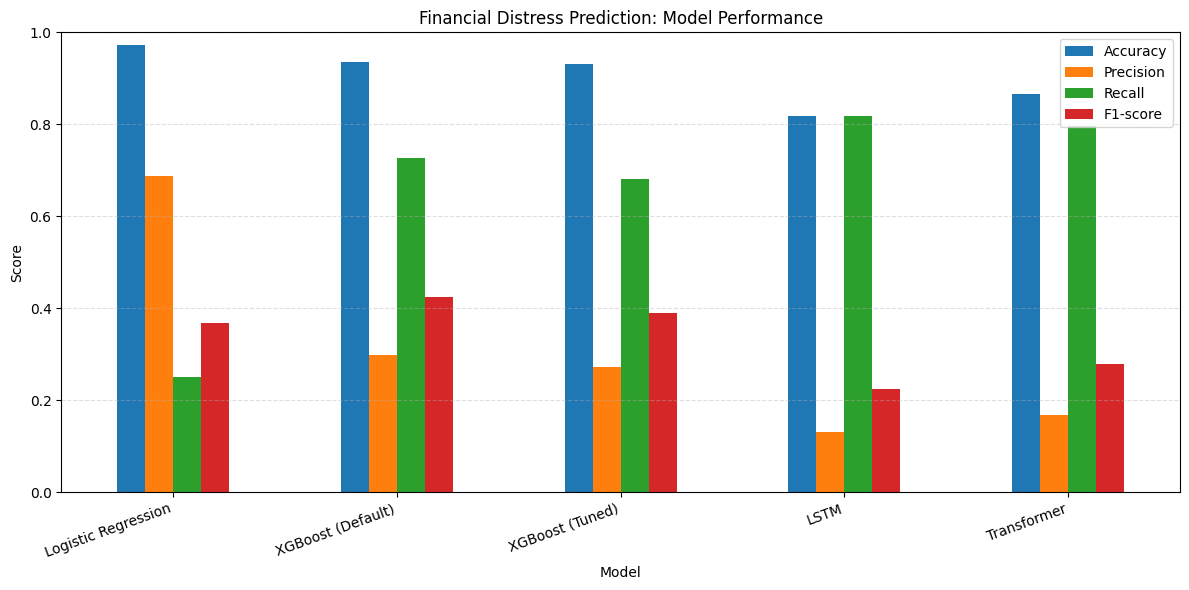

In [ ]:

# STEP 15A: Compare model performance

import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "XGBoost (Default)",
        "XGBoost (Tuned)",
        "LSTM",
        "Transformer"
    ],
    "Accuracy": [0.9721, 0.9362, 0.9311, 0.8182, 0.8666],
    "Precision": [0.6875, 0.2991, 0.2727, 0.1304, 0.1683],
    "Recall": [0.2500, 0.7273, 0.6818, 0.8182, 0.7955],
    "F1-score": [0.3667, 0.4238, 0.3896, 0.2250, 0.2778]
})

print(results.round(4).to_string(index=False))

ax = results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(12, 6), ylim=(0, 1))

ax.set_title("Financial Distress Prediction: Model Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


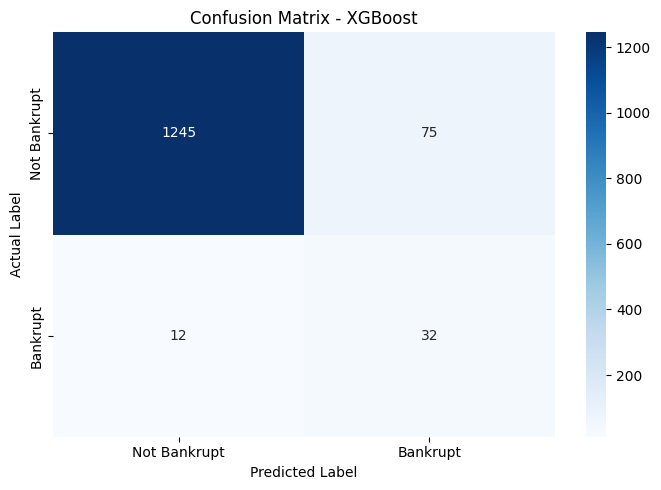

TN: 1245 | FP: 75
FN: 12 | TP: 32


In [ ]:

# STEP 15B: Confusion matrix for XGBoost

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Use the existing default-threshold XGBoost predictions
cm = confusion_matrix(y_test, xgb_model.predict(X_test_selected))

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Bankrupt", "Bankrupt"],
    yticklabels=["Not Bankrupt", "Bankrupt"]
)

plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("TN:", cm[0, 0], "| FP:", cm[0, 1])
print("FN:", cm[1, 0], "| TP:", cm[1, 1])


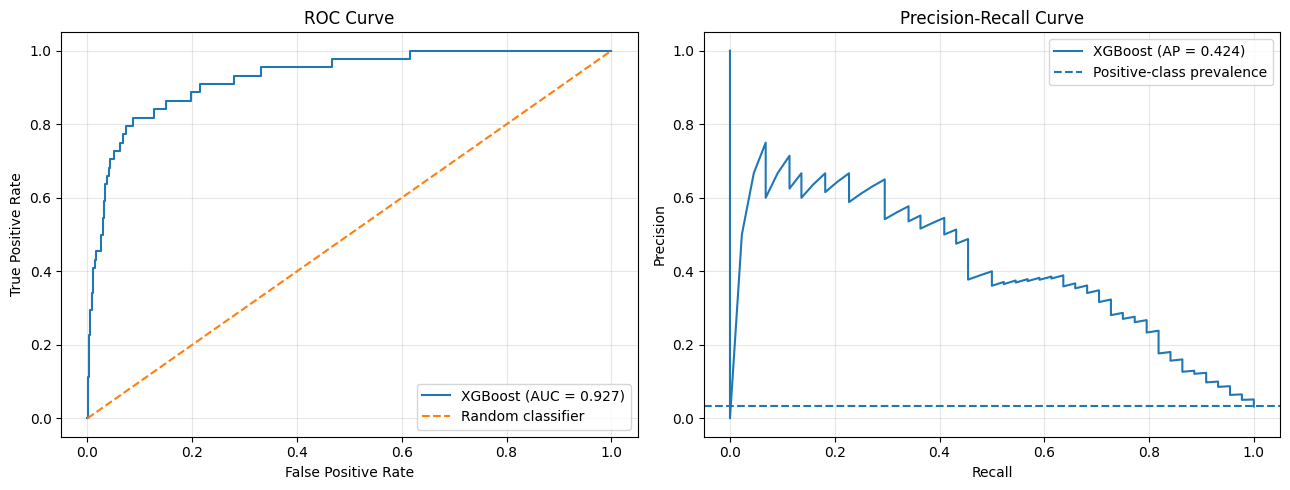

ROC-AUC: 0.9272
PR-AUC (Average Precision): 0.4244


In [ ]:

# STEP 15C: ROC and Precision-Recall curves for XGBoost

import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

# Predicted probabilities, not class labels
xgb_probs = xgb_model.predict_proba(X_test_selected)[:, 1]

fpr, tpr, _ = roc_curve(y_test, xgb_probs)
roc_auc = roc_auc_score(y_test, xgb_probs)

precision_vals, recall_vals, _ = precision_recall_curve(
    y_test, xgb_probs
)
pr_auc = average_precision_score(y_test, xgb_probs)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC curve
axes[0].plot(fpr, tpr, label=f"XGBoost (AUC = {roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Precision-Recall curve
axes[1].plot(
    recall_vals, precision_vals,
    label=f"XGBoost (AP = {pr_auc:.3f})"
)
axes[1].axhline(
    y=float(y_test.mean()),
    linestyle="--",
    label="Positive-class prevalence"
)
axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC (Average Precision):", round(pr_auc, 4))


In [ ]:

# FINAL STEP: Consolidated model results

final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "XGBoost (Default)",
        "XGBoost (Tuned)",
        "LSTM",
        "Transformer"
    ],
    "Accuracy": [0.9721, 0.9362, 0.9311, 0.8182, 0.8666],
    "Precision": [0.6875, 0.2991, 0.2727, 0.1304, 0.1683],
    "Recall": [0.2500, 0.7273, 0.6818, 0.8182, 0.7955],
    "F1-score": [0.3667, 0.4238, 0.3896, 0.2250, 0.2778],
    "ROC-AUC": [0.9316, 0.9272, 0.9252, 0.8987, 0.9145],
    "PR-AUC": [0.4441, 0.4244, 0.4507, 0.3084, 0.3829]
})

display(final_results.round(4))

print("\nBest F1-score model:",
      final_results.loc[final_results["F1-score"].idxmax(), "Model"])
print("Best PR-AUC model:",
      final_results.loc[final_results["PR-AUC"].idxmax(), "Model"])


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.9721,0.6875,0.2500,0.3667,0.9316,0.4441
1,XGBoost (Default),0.9362,0.2991,0.7273,0.4238,0.9272,0.4244
2,XGBoost (Tuned),0.9311,0.2727,0.6818,0.3896,0.9252,0.4507
3,LSTM,0.8182,0.1304,0.8182,0.2250,0.8987,0.3084
4,Transformer,0.8666,0.1683,0.7955,0.2778,0.9145,0.3829



Best F1-score model: XGBoost (Default)
Best PR-AUC model: XGBoost (Tuned)


In [ ]:
print("Test features:", X_test_selected.shape)
print("Test labels:", y_test.shape)

In [ ]:
print("Training features:", X_train_selected.shape)
print("Training labels:", y_train.shape)